# Tech Challenge · Fase 2 · Projeto 1
## Otimização dos modelos de diagnóstico com algoritmo genético + interpretação com LLM

Gabriel Wesley (RM376899) · Gustavo Leite (RM375733) · Luiz Fellipe (RM376854)

Roteiro deste notebook:

1. Dados e ponto de partida (modelos da Fase 1)
2. Algoritmo genético: codificação, operadores, fitness, execução ao vivo
3. Experimentos e comparação original × otimizado
4. LLM: contexto, prompts, resposta, avaliação, fallback
5. A API: chamadas e retornos
6. Escalabilidade, monitoramento e testes

> Projeto educacional de apoio à triagem. Não confirma nem descarta câncer e não substitui a avaliação médica.

### 0.1 Ambiente

In [1]:
import os, sys, json, warnings
from pathlib import Path
# raiz do projeto: guardada na 1ª execução, para a célula poder rodar de novo sem mudar de pasta
ROOT = globals().get('ROOT') or next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 120)

from src.config import load_env
load_env()  # lê o .env (chave do Groq); variáveis já exportadas têm prioridade

# 'groq' = LLM real (gasta cota); 'offline' = template determinístico, sem chave
PROVIDER = 'groq' if (os.getenv('GROQ_API_KEY') or os.getenv('LLM_API_KEY')) else 'offline'
print('Provedor da LLM neste notebook:', PROVIDER)

Provedor da LLM neste notebook: groq


## 1. Dados e ponto de partida

### 1.1 Mesmo dataset e mesmo split da Fase 1
Mesmas regras de limpeza e o mesmo split estratificado 80/20 (`random_state=42`): as 114 pacientes de teste são exatamente as da Fase 1, o que torna justa a comparação original × otimizado. **O AG nunca vê o teste.**

In [2]:
from src.data import load_split
data = load_split()
pd.DataFrame({
    'amostras': [len(data.y_train), len(data.y_test)],
    'malignos': [int(data.y_train.sum()), int(data.y_test.sum())],
    'benignos': [int((data.y_train == 0).sum()), int((data.y_test == 0).sum())],
}, index=['treino', 'teste'])

,amostras,malignos,benignos
treino,455,170,285
teste,114,42,72


### 1.2 Os modelos originais da Fase 1
Regressão Logística e Random Forest com os hiperparâmetros fixos da Fase 1 e limiar 0,5. São a linha de base de todas as comparações.

In [3]:
from src.models import BASELINE_PARAMS
for nome, params in BASELINE_PARAMS.items():
    print(f'{nome}: {params}')

logistic_regression: {'C': 1.0, 'l1_ratio': 0.0, 'class_weight': 'balanced', 'threshold': 0.5}
random_forest: {'n_estimators': 500, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'criterion': 'gini', 'class_weight': 'balanced', 'bootstrap': True, 'threshold': 0.5}


In [4]:
res = json.load(open('reports/results/experiments.json', encoding='utf-8'))
def metricas(t):
    return {'recall': round(t['recall'], 3), 'precisão': round(t['precision'], 3), 'F1': round(t['f1'], 3),
            'ROC-AUC': round(t['roc_auc'], 3), 'falsos negativos': t['false_negatives'],
            'falsos positivos': t['false_positives']}
pd.DataFrame.from_dict({r['display_name']: metricas(r['baseline']['test_metrics'])
                        for r in res['models'].values()}, orient='index')

,recall,precisão,F1,ROC-AUC,falsos negativos,falsos positivos
Regressão Logística,0.952,0.976,0.964,0.995,2,1
Random Forest,0.929,1.000,0.963,0.997,3,0


## 2. Algoritmo genético (implementado do zero, em `src/ga/`)

### 2.1 Codificação: cada gene é um hiperparâmetro
O cromossomo é um vetor em [0, 1]ᵈ. Cada gene é decodificado conforme o seu tipo: real (com escala log para `C`), inteiro ou categórico. **O limiar de decisão também é um gene**: é ele que troca falsos negativos por falsos positivos.

In [5]:
from src.spaces import SPACES
from src.ga.search_space import CategoricalGene, FloatGene, IntGene
def descreve(g):
    if isinstance(g, FloatGene):
        return 'real' + (' (log)' if g.log else ''), f'{g.low} … {g.high}'
    if isinstance(g, IntGene):
        return 'inteiro', f'{g.low} … {g.high}'
    return 'categórico', ', '.join(map(str, g.choices))
linhas = [{'modelo': m, 'gene': g.name, 'tipo': descreve(g)[0], 'valores': descreve(g)[1]}
          for m, space in SPACES.items() for g in space.genes]
pd.DataFrame(linhas)

,modelo,gene,tipo,valores
0,logistic_regression,C,real (log),0.001 … 100.0
1,logistic_regression,l1_ratio,real,0.0 … 1.0
2,logistic_regression,class_weight,categórico,"None, balanced"
3,logistic_regression,threshold,real,0.2 … 0.8
4,random_forest,n_estimators,inteiro,50 … 300
5,random_forest,max_depth,categórico,"3, 5, 8, 12, 20, None"
6,random_forest,min_samples_split,inteiro,2 … 20
7,random_forest,min_samples_leaf,inteiro,1 … 10
8,random_forest,max_features,categórico,"sqrt, log2, 0.3, 0.5, 0.8"
9,random_forest,criterion,categórico,"gini, entropy"


In [6]:
space = SPACES['logistic_regression']
cromossomo = np.random.default_rng(7).random(space.size)
print('cromossomo:', cromossomo.round(3))
print('decodificado:', space.decode(cromossomo))

cromossomo: [0.625 0.897 0.776 0.225]
decodificado: {'C': 1.335, 'l1_ratio': 0.9, 'class_weight': 'balanced', 'threshold': 0.34}


### 2.2 Operadores genéticos
Seleção (torneio, roleta, ranking), cruzamento (uniforme, um ponto, BLX-α) e mutação (gaussiana, uniforme). Exemplo com dois pais:

In [7]:
from src.ga.operators import blx_alpha_crossover, gaussian_mutation, tournament_selection
rng = np.random.default_rng(1)
pai, mae = rng.random(space.size), rng.random(space.size)
filho1, filho2 = blx_alpha_crossover(pai, mae, rng, alpha=0.5)
mutante = gaussian_mutation(filho1, rate=0.5, rng=rng, sigma=0.1)
pd.DataFrame([pai, mae, filho1, mutante], columns=space.names,
             index=['pai', 'mãe', 'filho (BLX-α)', 'filho após mutação']).round(3)

,C,l1_ratio,class_weight,threshold
pai,0.512,0.950,0.144,0.949
mãe,0.312,0.423,0.828,0.409
filho (BLX-α),0.432,0.189,0.833,0.720
filho após mutação,0.432,0.161,0.962,0.821


In [8]:
fitness_pop = np.array([0.91, 0.95, 0.80, 0.97, 0.88, 0.93])
escolhidos = tournament_selection(fitness_pop, n=6, rng=np.random.default_rng(3), k=3)
print('fitness da população:', fitness_pop)
print('índices escolhidos por torneio (k=3):', escolhidos, '→ os melhores aparecem mais')

fitness da população: [0.91 0.95 0.8  0.97 0.88 0.93]
índices escolhidos por torneio (k=3): [1 1 3 1 3 0] → os melhores aparecem mais


### 2.3 Função fitness
Validação cruzada 5-fold **só no treino**:  
`fitness = 0,45·Recall + 0,35·F1 + 0,20·ROC-AUC`  
O recall pesa mais (não deixar passar câncer); o F1 impede a solução trivial "tudo maligno".

In [9]:
from src.fitness import CVFitness
fitness = CVFitness('logistic_regression', data.X_train, data.y_train)
score, met = fitness(BASELINE_PARAMS['logistic_regression'])
print('fitness do modelo original (Fase 1):', round(score, 4))
pd.Series(met).round(4)

fitness do modelo original (Fase 1): 0.9671


accuracy           0.9714
precision          0.9645
recall             0.9588
f1                 0.9617
roc_auc            0.9950
false_negatives    7.0000
false_positives    6.0000
fitness            0.9671
dtype: float64

### 2.4 O AG rodando ao vivo
Regressão Logística, população 10, 6 gerações, BLX-α e torneio. Leva poucos segundos.

In [10]:
from src.ga import GAConfig, GeneticAlgorithm
cfg = GAConfig(population_size=10, generations=6, crossover='blx', mutation_rate=0.15, seed=1)
resultado = GeneticAlgorithm(space, fitness, cfg).run()
hist = pd.DataFrame([{'geração': h.generation, 'melhor': round(h.best_fitness, 4),
                      'média': round(h.mean_fitness, 4), 'diversidade': round(h.diversity, 3),
                      'avaliações': h.evaluations} for h in resultado.history])
hist

,geração,melhor,média,diversidade,avaliações
0,0,0.9739,0.9090,0.276,10
1,1,0.9739,0.9667,0.208,16
2,2,0.9739,0.9708,0.153,23
3,3,0.9739,0.9727,0.086,26
4,4,0.9739,0.9738,0.015,28
5,5,0.9739,0.9729,0.031,32
6,6,0.9739,0.9735,0.047,38


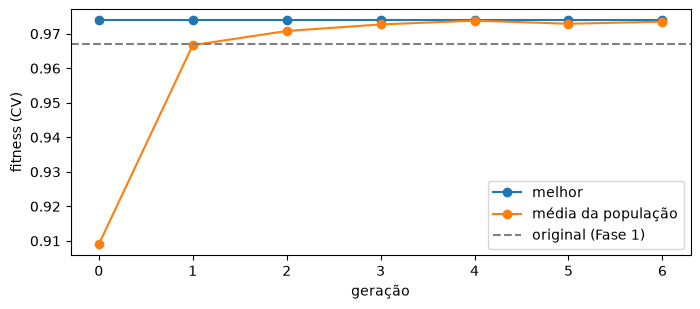

melhor indivíduo: {'C': 64.3111, 'l1_ratio': 0.72, 'class_weight': 'balanced', 'threshold': 0.37} | fitness 0.9739


In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(hist['geração'], hist['melhor'], marker='o', label='melhor')
ax.plot(hist['geração'], hist['média'], marker='o', label='média da população')
ax.axhline(score, ls='--', color='grey', label='original (Fase 1)')
ax.set_xlabel('geração'); ax.set_ylabel('fitness (CV)'); ax.legend(); plt.show()
print('melhor indivíduo:', resultado.best_params, '| fitness', round(resultado.best_fitness, 4))

## 3. Experimentos e comparação

### 3.1 As 5 configurações do AG
Definidas em `configs/experiments.yaml` e rodadas por `python -m scripts.run_experiments` para os dois modelos. Os resultados abaixo foram salvos dessa execução.

In [12]:
import yaml
cfgs = yaml.safe_load(open('configs/experiments.yaml', encoding='utf-8'))['experiments']
cols = ['population_size', 'generations', 'mutation_rate', 'selection', 'crossover', 'mutation', 'description']
pd.DataFrame(cfgs).T.reindex(columns=cols)

,population_size,generations,mutation_rate,selection,crossover,mutation,description
E1_pop_pequena,10,8,0.1,tournament,uniform,gaussian,"População pequena, poucas gerações, mutação baixa — linha de base do AG"
E2_blx_torneio,16,12,0.15,tournament,blx,gaussian,"População média, crossover BLX-α (codificação real) e torneio"
E3_roleta_um_ponto,24,10,0.05,roulette,one_point,gaussian,"População maior, roleta + crossover de um ponto, mutação baixa"
E4_alta_mutacao,16,12,0.3,rank,uniform,uniform,Mutação alta e uniforme com seleção por ranking — foco em exploração
E5_semeado_baseline,16,12,0.15,tournament,blx,gaussian,"Igual ao E2, mas com o modelo original da Fase 1 na população inicial"


### 3.2 Resultados de todos os experimentos
`cv_fitness` é o que o AG otimiza (treino). As demais colunas são no **teste**. A busca aleatória usa o mesmo orçamento de avaliações do experimento de referência.

In [13]:
rows = []
for model, r in res['models'].items():
    todos = {'original (Fase 1)': r['baseline'], **r['experiments'], 'busca aleatória': r['random_search']}
    for nome, rec in todos.items():
        rows.append({'modelo': r['display_name'], 'configuração': nome, 'cv_fitness': round(rec['cv_fitness'], 4),
                     'CV 5×3': round(rec['robust_cv']['fitness']['mean'], 4), **metricas(rec['test_metrics'])})
pd.DataFrame(rows)

,modelo,configuração,cv_fitness,CV 5×3,recall,precisão,F1,ROC-AUC,falsos negativos,falsos positivos
0,Regressão Logística,original (Fase 1),0.9671,0.9659,0.952,0.976,0.964,0.995,2,1
1,Regressão Logística,E1_pop_pequena,0.9771,0.9703,0.976,0.953,0.965,0.997,1,2
2,Regressão Logística,E2_blx_torneio,0.9770,0.9699,0.952,0.952,0.952,0.994,2,2
3,Regressão Logística,E3_roleta_um_ponto,0.9780,0.9678,0.976,0.911,0.943,0.997,1,4
4,Regressão Logística,E4_alta_mutacao,0.9763,0.9694,0.976,0.976,0.976,0.997,1,1
5,Regressão Logística,E5_semeado_baseline,0.9770,0.9699,0.952,0.952,0.952,0.994,2,2
6,Regressão Logística,busca aleatória,0.9763,0.9703,0.976,0.976,0.976,0.997,1,1
7,Random Forest,original (Fase 1),0.9621,0.9516,0.929,1.000,0.963,0.997,3,0
8,Random Forest,E1_pop_pequena,0.9676,0.9606,0.929,0.975,0.951,0.998,3,1
9,Random Forest,E2_blx_torneio,0.9659,0.9579,0.929,0.975,0.951,0.996,3,1


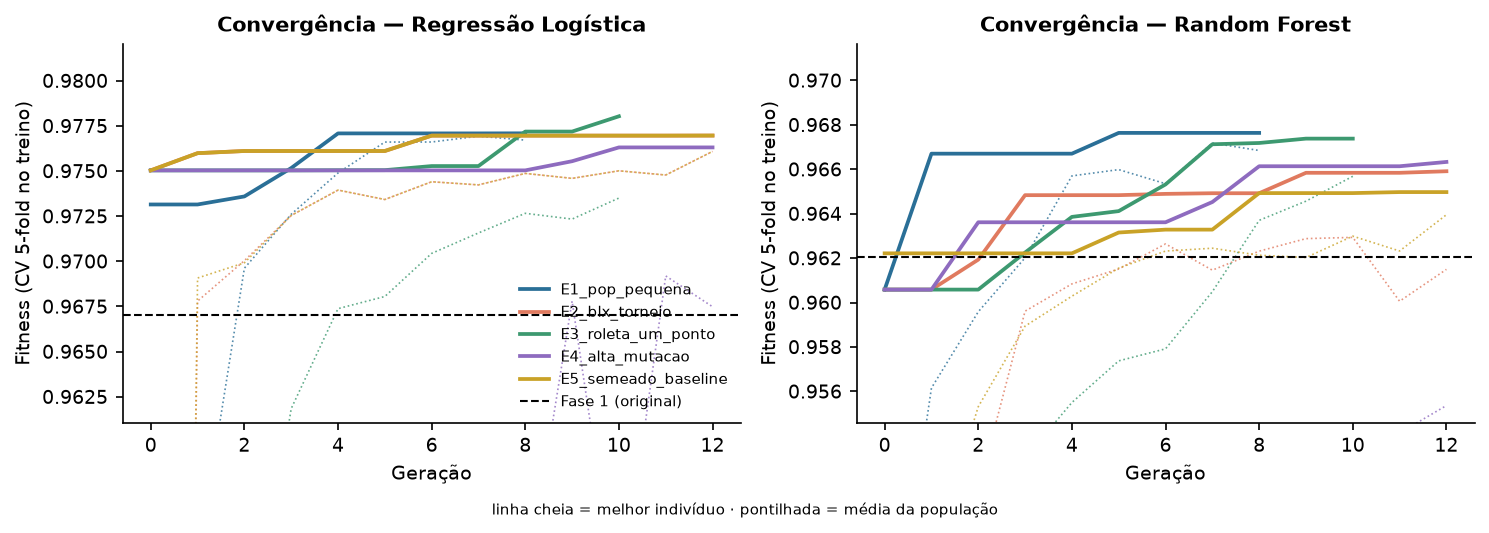

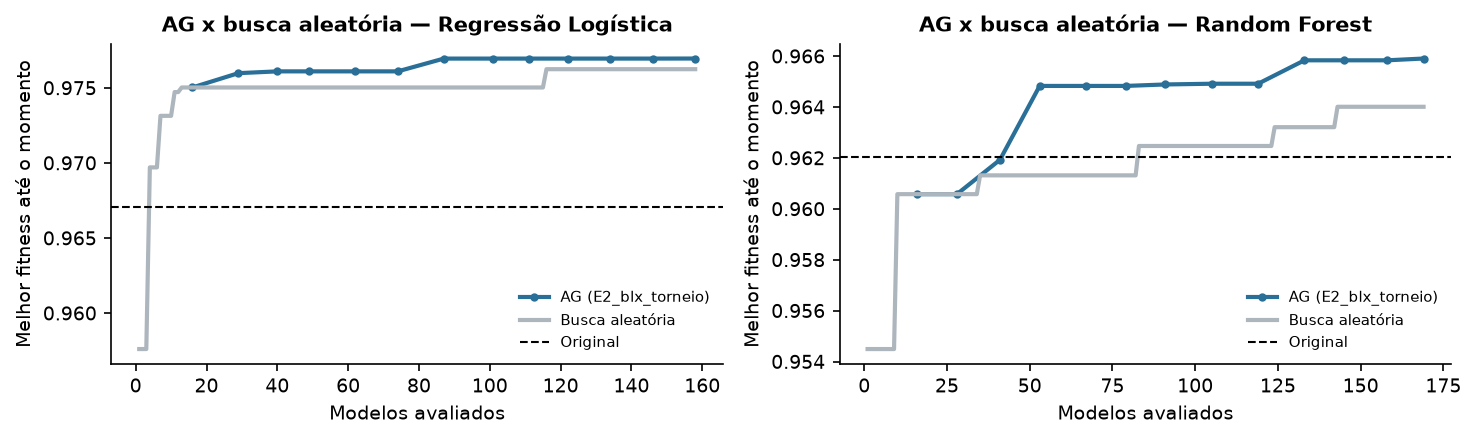

In [14]:
for f in ['convergencia_ag.png', 'ag_vs_busca_aleatoria.png']:
    display(Image(f'reports/figures/{f}'))

### 3.3 Modelo escolhido e o ganho no teste
A escolha é feita pela validação cruzada repetida 5×3 (mais robusta), **nunca pelo teste**.

In [15]:
sel = res['selected']
base = res['models'][sel['model']]['baseline']['test_metrics']
print('Selecionado:', res['models'][sel['model']]['display_name'], '/', sel['source'])
print('Hiperparâmetros:', sel['params'])
pd.DataFrame.from_dict({'original (Fase 1)': metricas(base), 'otimizado (AG)': metricas(sel['test_metrics'])},
                       orient='index')

Selecionado: Regressão Logística / E1_pop_pequena
Hiperparâmetros: {'C': 0.5928, 'l1_ratio': 0.11, 'class_weight': None, 'threshold': 0.26}


,recall,precisão,F1,ROC-AUC,falsos negativos,falsos positivos
original (Fase 1),0.952,0.976,0.964,0.995,2,1
otimizado (AG),0.976,0.953,0.965,0.997,1,2


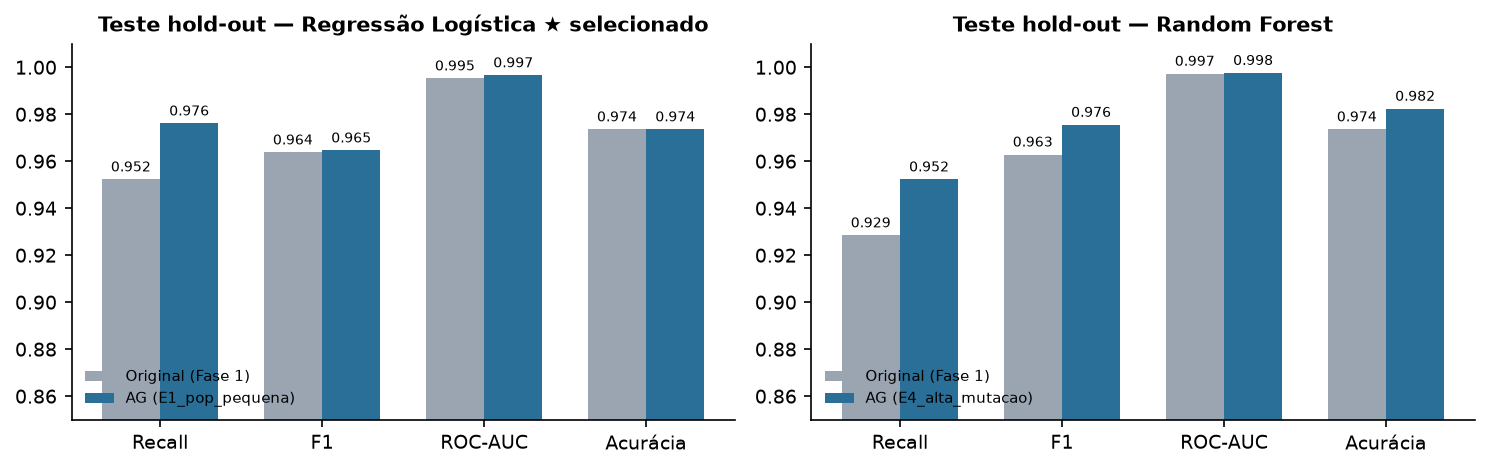

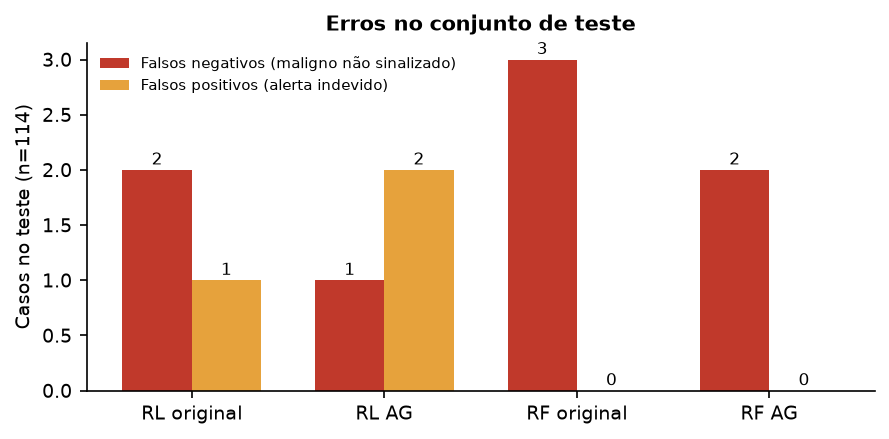

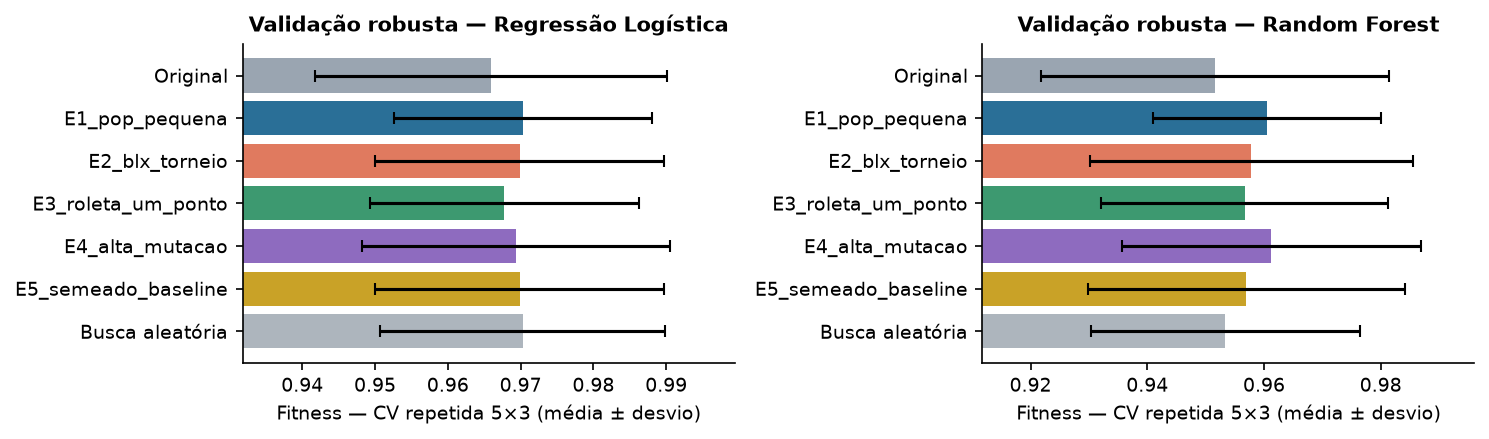

In [16]:
for f in ['comparativo_teste.png', 'erros_teste.png', 'validacao_robusta.png']:
    display(Image(f'reports/figures/{f}'))

### 3.4 O modelo em produção prevendo uma paciente

In [17]:
import joblib
model = joblib.load('models/best_model.joblib')
card = json.load(open('models/model_card.json', encoding='utf-8'))
paciente = data.X_test[data.y_test == 1].iloc[[0]]
p = model.predict_proba(paciente)[:, 1][0]
print(f'Paciente #{paciente.index[0]} (real: maligno) → probabilidade {p:.1%}, limiar {model.threshold:.2f} →',
      'ALERTA' if p >= model.threshold else 'sem alerta')

Paciente #250 (real: maligno) → probabilidade 100.0%, limiar 0.26 → ALERTA


## 4. Interpretação com LLM

### 4.1 Provedor
Interface única para APIs compatíveis com OpenAI (Groq, Ollama, OpenAI) e Anthropic. Padrão: Groq com `openai/gpt-oss-120b`. Respostas 429 (limite de taxa) são repetidas respeitando o `Retry-After`.

In [18]:
from src.llm import DiagnosisInterpreter, get_provider
provider = get_provider(PROVIDER)
interp = DiagnosisInterpreter(model, card, provider)
print('provedor:', provider.name, '| modelo:', provider.model)

provedor: groq | modelo: openai/gpt-oss-120b


### 4.2 Contexto numérico (grounding)
A LLM **não recebe a paciente crua**: recebe a probabilidade, o limiar, a faixa de risco e os 5 fatores que mais pesaram para *esta* paciente (por oclusão), com as médias de benignos e malignos. São os únicos números que ela pode usar.

In [19]:
from src.explain import build_case_context
contexto = build_case_context(model, card, paciente)
print({k: v for k, v in contexto.items() if k not in ('fatores_principais', 'desempenho_modelo')})
pd.DataFrame(contexto['fatores_principais'])

{'probabilidade_malignidade': 1.0, 'probabilidade_percentual': 100.0, 'limiar_decisao': 0.26, 'classificacao_modelo': 'suspeito de malignidade', 'faixa_risco': 'alto', 'modelo': {'nome': 'Regressão Logística', 'origem': 'otimizado por algoritmo genético', 'recall_teste_percentual': 97.6, 'precisao_teste_percentual': 95.3, 'roc_auc_teste': 0.997, 'falsos_negativos_teste': 1, 'falsos_positivos_teste': 2, 'amostras_teste': 114}}

,atributo,nome,valor,mediana_treino,impacto,direcao,media_benignos,media_malignos
0,radius_se,raio (erro-padrão),1.004,0.3274,0.0,aumenta o risco,0.2861,0.6208
1,concave points_mean,pontos côncavos (média),0.131,0.0333,0.0,aumenta o risco,0.0253,0.0888
2,radius_worst,raio (pior valor),25.580,14.9200,0.0,aumenta o risco,13.4114,21.2806
3,area_worst,área (pior valor),2010.000,683.4000,0.0,aumenta o risco,561.8123,1441.7206
4,area_se,área (erro-padrão),137.900,24.8700,0.0,aumenta o risco,21.3519,74.6864


### 4.3 Prompt engineering: as 3 estratégias
`basico` (só a pergunta), `estruturado` (persona, regras e JSON) e `few_shot` (estruturado + exemplo).

In [20]:
from src.llm.prompts import case_prompt
for estrategia in ['basico', 'estruturado', 'few_shot']:
    system, user, json_mode = case_prompt(contexto, estrategia)
    print(f'{estrategia:<12} prompt de sistema: {len(system):>5} caracteres | usuário: {len(user):>5} | json_mode={json_mode}')
system, user, _ = case_prompt(contexto, 'few_shot')
print('\n--- PROMPT DE SISTEMA (few_shot) ---\n' + system)

basico       prompt de sistema:    26 caracteres | usuário:  1862 | json_mode=False
estruturado  prompt de sistema:  1074 caracteres | usuário:  2317 | json_mode=True
few_shot     prompt de sistema:  1074 caracteres | usuário:  4571 | json_mode=True

--- PROMPT DE SISTEMA (few_shot) ---
Você é um assistente de apoio à decisão clínica em um hospital universitário.
Seu público são médicos(as) mastologistas e patologistas. Você explica, em português do Brasil,
o resultado de um modelo de machine learning que estima a probabilidade de malignidade de uma
massa mamária a partir de medidas morfológicas de núcleos celulares (exame de PAAF digitalizado).

Regras obrigatórias:
1. Use SOMENTE os números presentes no CONTEXTO. Não invente valores, percentuais ou estatísticas.
2. Nunca afirme diagnóstico definitivo. Não use expressões como "confirma câncer", "é maligno",
   "descarta câncer" ou "não há câncer". Fale em probabilidade estimada e sinal de alerta.
3. Cite os fatores pelo nome em portug

### 4.4 Chamada à LLM: resposta bruta → JSON → texto para o médico

In [21]:
out = interp.explain_case(paciente, strategy='few_shot')
print(f'provedor={out.provider} modelo={out.model} latência={out.latency_s}s fallback={out.used_fallback}')
print('tokens:', {k: out.usage[k] for k in ('prompt_tokens', 'completion_tokens', 'total_tokens') if k in out.usage})
print('\n--- RESPOSTA BRUTA ---\n' + out.raw[:900])

provedor=groq modelo=openai/gpt-oss-120b latência=1.298s fallback=False
tokens: {'prompt_tokens': 1886, 'completion_tokens': 307, 'total_tokens': 2193}

--- RESPOSTA BRUTA ---
{
  "resumo": "O modelo estimou probabilidade de malignidade de 100.0%, bem acima do limiar de decisão de 0.26. A amostra está na faixa de risco alto e foi classificada como suspeita de malignidade.",
  "fatores_relevantes": [
    "Raio (pior valor) de 25.58, acima da média de malignos (21.2806) — aumenta o risco.",
    "Área (pior valor) de 2010.0, maior que a média de malignos (1441.7206) — aumenta o risco.",
    "Pontos côncavos (média) de 0.131, acima da média de malignos (0.0888) — aumenta o risco."
  ],
  "confiabilidade": "No teste, o modelo apresentou recall de 97.6% e 1 falso negativo em 114 amostras, com precisão de 95.3% e 2 falsos positivos.",
  "recomendacao": "Priorizar avaliação clínica detalhada e considerar confirmação histopatológica, sempre de acordo com o julgamento do médico.",
  "limitacoes"

In [22]:
print('JSON válido:', out.valid_json)
print(out.text)

JSON válido: True
Resumo: O modelo estimou probabilidade de malignidade de 100.0%, bem acima do limiar de decisão de 0.26. A amostra está na faixa de risco alto e foi classificada como suspeita de malignidade.

Fatores relevantes:
• Raio (pior valor) de 25.58, acima da média de malignos (21.2806) — aumenta o risco.
• Área (pior valor) de 2010.0, maior que a média de malignos (1441.7206) — aumenta o risco.
• Pontos côncavos (média) de 0.131, acima da média de malignos (0.0888) — aumenta o risco.

Confiabilidade: No teste, o modelo apresentou recall de 97.6% e 1 falso negativo em 114 amostras, com precisão de 95.3% e 2 falsos positivos.

Recomendação: Priorizar avaliação clínica detalhada e considerar confirmação histopatológica, sempre de acordo com o julgamento do médico.

Limitações: O modelo não incorpora histórico clínico, exame físico nem achados de imagem.

Aviso: Apoio à decisão: não confirma nem descarta câncer e não substitui a avaliação médica.


### 4.5 Avaliação automática da resposta (e o LLM juiz)
Formato, fidelidade numérica (números inventados), cobertura dos fatores, coerência com o modelo, segurança (aviso e sem diagnóstico definitivo) e legibilidade. O juiz é outra chamada à LLM que dá notas de 1 a 5.

In [23]:
from src.llm.evaluation import evaluate_interpretation, llm_judge
notas = evaluate_interpretation(out)
juiz = llm_judge(provider, out)  # None no provedor offline
display(pd.Series({k: v for k, v in notas.items() if k not in ('violacoes',)}, name='notas'))
print('LLM juiz:', juiz if juiz else '(indisponível no offline)')

formato                 1.0
fidelidade              1.0
cobertura               1.0
coerencia               1.0
seguranca               1.0
legibilidade            1.0
score_geral             1.0
numeros_inventados       []
latencia_s            1.298
fallback              False
palavras                152
Name: notas, dtype: object

LLM juiz: {'clareza': 5.0, 'utilidade_clinica': 4.0, 'fidelidade': 5.0, 'seguranca': 5.0, 'media': 4.75, 'comentario': 'A explicação está escrita em linguagem clara para médicos, sem termos técnicos de computação, e descreve de forma objetiva a alta probabilidade de malignidade, os principais fatores de risco e as métricas de desempenho do modelo. Ajuda o clínico a decidir pela investigação adicional (ex.: biópsia), mas não prescreve um diagnóstico definitivo, mantendo a segurança ao enfatizar que se trata de apoio à decisão. A única limitação é que poderia incluir sugestões mais concretas de próximos passos (por exemplo, encaminhamento imediato para imagem ou biópsia), o que elevaria a utilidade clínica.'}


### 4.6 Por que o prompt importa: básico × few-shot na mesma paciente

In [24]:
basico = interp.explain_case(paciente, strategy='basico')
nb = evaluate_interpretation(basico)
pd.DataFrame({'básico': {k: nb[k] for k in ('formato', 'fidelidade', 'seguranca', 'score_geral', 'palavras')},
              'few-shot': {k: notas[k] for k in ('formato', 'fidelidade', 'seguranca', 'score_geral', 'palavras')}})

,básico,few-shot
formato,0.00,1.0
fidelidade,1.00,1.0
seguranca,0.50,1.0
score_geral,0.75,1.0
palavras,487.00,152.0


### 4.7 Pergunta livre do médico

In [25]:
resposta = interp.ask(paciente, 'Quais medidas mais contribuíram para esse resultado e o que devo '
                     'considerar antes de pedir biópsia?')
print(resposta.text)

resposta: Os principais atributos que aumentam o risco são: raio (erro‑padrão) = 1.004 (média dos benignos = 0.2861, média dos malignos = 0.6208); pontos côncavos (média) = 0.131 (média benignos = 0.0253, média malignos = 0.0888); raio (pior valor) = 25.58 (média benignos = 13.4114, média malignos = 21.2806); área (pior valor) = 2010 (média benignos = 561.8123, média malignos = 1441.7206); área (erro‑padrão) = 137.9 (média benignos = 21.3519, média malignos = 74.6864). Todos esses valores estão acima das médias observadas tanto em casos benignos quanto malignos, indicando forte contribuição para a classificação de "suspeito de malignidade" com risco alto. Antes de decidir pela biópsia, considere: correlação clínica com imagem mamográfica ou ultrassonográfica; presença de fatores de risco individuais (idade, história familiar, densidade mamária); resultados de exames complementares (citoscopia, marcadores tumorais); e a possibilidade de repetir a aspiração ou obter material adicional pa

### 4.8 Fallback: o que acontece quando a LLM falha
Simulamos uma falha de API (sem gastar cota). A resposta vem do template offline **e isso fica explícito**: `used_fallback=True`, com o motivo.

In [26]:
from src.llm import LLMAPIError
class ProvedorQueFalha:
    name, model = 'groq', 'simulado'
    def generate(self, *a, **k):
        raise LLMAPIError('HTTP 429 — limite de taxa esgotado (simulado)')
falha = DiagnosisInterpreter(model, card, ProvedorQueFalha()).explain_case(paciente)
print(f'provedor={falha.provider} fallback={falha.used_fallback} tipo={falha.error_kind}')
print('motivo:', falha.error)

LLM falhou (groq, api): HTTP 429 — limite de taxa esgotado (simulado)


provedor=offline fallback=True tipo=api
motivo: HTTP 429 — limite de taxa esgotado (simulado)


### 4.9 Insights para a equipe clínica (original × otimizado)

In [27]:
relatorio = interp.explain_performance(res)
print(relatorio.text)

https://api.groq.com/openai/v1: HTTP 429; nova tentativa 1/5 em 1.5s


Resumo: O modelo otimizado aumentou o recall de 95,2% para 97,6% reduzindo falsos negativos de 2 para 1, porém a precisão caiu de 97,6% para 95,3% aumentando falsos positivos de 1 para 2; as demais métricas (acurácia, ROC AUC e F1) permaneceram praticamente iguais.

Insights:
• Com 42 casos malignos no teste, o modelo original deixou de identificar 2 (4,8%) enquanto o otimizado deixou apenas 1 (2,4%); isso significa um caso a menos de câncer não sinalizado.
• A precisão caiu 2,3 pontos percentuais, passando de 97,6% para 95,3%, o que gera um falso positivo a mais (de 1 para 2), ou seja, um paciente saudável pode ser encaminhado desnecessariamente para exames adicionais.
• O ROC AUC melhorou de 0,995 para 0,997, indicando que a capacidade discriminatória do modelo continua excelente, mas a mudança é marginal e não traz ganho clínico relevante.
• O F1 score praticamente não mudou (0,964 para 0,965), reforçando que o balanço entre recall e precisão permanece estável.
• O threshold foi red

### 4.10 Avaliação completa salva (10 pacientes × 3 estratégias, com juiz)
Gerada por `python -m scripts.evaluate_llm --provider groq --judge groq`. É a execução citada no relatório.

In [28]:
ev = json.load(open('reports/results/llm_evaluation_groq.json', encoding='utf-8'))
print(f"provedor={ev['provider']} modelo={ev['model']} juiz={ev['judge_model']} casos={ev['cases']} falhas={ev['falhas']}")
pd.DataFrame(ev['summary']).T[['formato', 'fidelidade', 'cobertura', 'coerencia', 'seguranca',
                               'legibilidade', 'score_geral', 'juiz_media', 'palavras', 'latencia_s']]

provedor=groq modelo=openai/gpt-oss-120b juiz=openai/gpt-oss-120b casos=10 falhas={'api': 0, 'formato': 0, 'juiz': 0}


,formato,fidelidade,cobertura,coerencia,seguranca,legibilidade,score_geral,juiz_media,palavras,latencia_s
basico,0.0,0.9813,1.0000,1.0,0.5,1.0,0.7469,4.78,475.5,7.2798
estruturado,1.0,1.0000,0.9333,1.0,1.0,1.0,0.9889,4.65,151.0,9.7504
few_shot,1.0,1.0000,0.9000,1.0,1.0,1.0,0.9833,4.53,150.2,18.2329


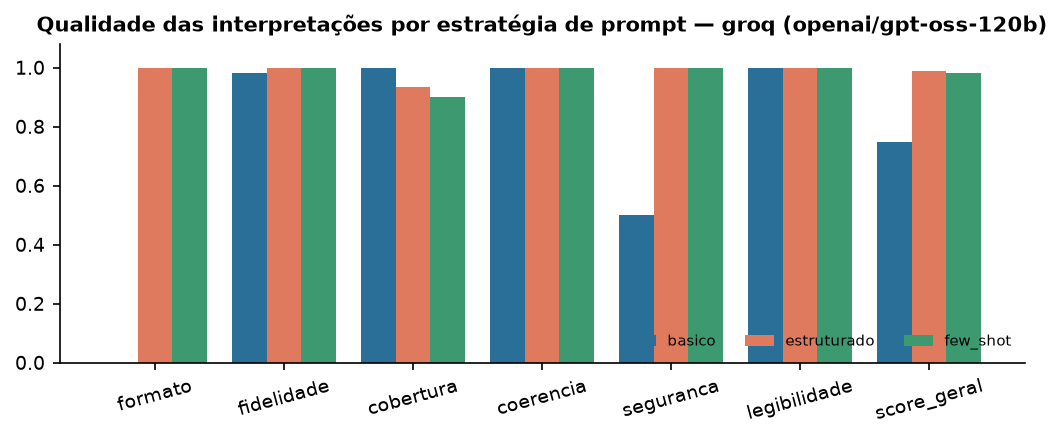

In [29]:
display(Image('reports/figures/llm_avaliacao_groq.png'))

## 5. A API: chamadas e retornos

A mesma lógica, servida por FastAPI (`src/api/main.py`). Aqui a API roda dentro do notebook (`TestClient`), sem precisar subir o servidor. É ela que a aplicação web consome.

In [30]:
os.environ['LOG_LEVEL'] = 'WARNING'  # os logs JSON de cada requisição ficam para a seção 6
from fastapi.testclient import TestClient
from src.api.main import app
api = TestClient(app).__enter__()
def mostra(r, chaves=None):
    corpo = r.json()
    if chaves:
        corpo = {k: corpo[k] for k in chaves}
    print(r.request.method, r.request.url.path, '→ HTTP', r.status_code)
    print(json.dumps(corpo, ensure_ascii=False, indent=2)[:1500])
mostra(api.get('/health'))
mostra(api.get('/model'), ['display_name', 'source', 'params'])

GET /health → HTTP 200
{
  "status": "ok"
}
GET /model → HTTP 200
{
  "display_name": "Regressão Logística",
  "source": "E1_pop_pequena",
  "params": {
    "C": 0.5928,
    "l1_ratio": 0.11,
    "class_weight": null,
    "threshold": 0.26
  }
}


In [31]:
amostra = paciente.iloc[0].to_dict()
mostra(api.post('/predict', json={'amostras': [amostra]}))

POST /predict → HTTP 200
{
  "modelo": "Regressão Logística",
  "origem": "E1_pop_pequena",
  "resultados": [
    {
      "probabilidade_malignidade": 1.0,
      "limiar": 0.26,
      "orientacao": "Encaminhar para avaliação médica"
    }
  ],
  "aviso": "Resultado de apoio à triagem. Não confirma nem descarta câncer e não substitui a avaliação médica."
}


In [32]:
r = api.post('/interpret', json={'amostra': amostra, 'estrategia': 'estruturado', 'provider': PROVIDER})
mostra(r, ['provider', 'model', 'latency_s', 'used_fallback', 'error', 'structured'])

{"ts": "2026-10-31T01:48:27.971956+00:00", "level": "WARNING", "logger": "src.llm.providers", "msg": "https://api.groq.com/openai/v1: HTTP 429; nova tentativa 1/5 em 6.5s", "request_id": "7b23d0ef5b45"}


{"ts": "2026-10-31T01:48:34.803974+00:00", "level": "WARNING", "logger": "src.llm.providers", "msg": "https://api.groq.com/openai/v1: HTTP 429; nova tentativa 2/5 em 3.5s", "request_id": "7b23d0ef5b45"}


POST /interpret → HTTP 200
{
  "provider": "groq",
  "model": "openai/gpt-oss-120b",
  "latency_s": 11.887,
  "used_fallback": false,
  "error": null,
  "structured": {
    "resumo": "O modelo estima 100% de probabilidade de malignidade, acima do limiar de decisão de 0,26, indicando risco alto.",
    "fatores_relevantes": [
      "raio (erro‑padrão): 1.004 (acima da média de benignos 0.2861 e dos malignos 0.6208) – aumenta o risco",
      "pontos côncavos (média): 0.131 (acima da média de benignos 0.0253 e dos malignos 0.0888) – aumenta o risco",
      "área (pior valor): 2010.0 (acima da média de benignos 561.8123 e dos malignos 1441.7206) – aumenta o risco"
    ],
    "confiabilidade": "No teste, o modelo apresentou recall de 97.6% e apenas 1 falso negativo entre 114 amostras, indicando alta sensibilidade.",
    "recomendacao": "Considerar avaliação clínica detalhada, incluindo biópsia ou correlação com imagem, para confirmar a necessidade de intervenção.",
    "limitacoes": "O model

In [33]:
r = api.get('/samples', params={'filtro': 'erros'})
print('GET /samples?filtro=erros → HTTP', r.status_code)
pd.DataFrame(r.json()['amostras'])[['indice', 'diagnostico_real', 'probabilidade', 'alerta', 'acertou']]

GET /samples?filtro=erros → HTTP 200


,indice,diagnostico_real,probabilidade,alerta,acertou
0,456,B,0.2877,True,False
1,73,M,0.0778,False,False
2,455,B,0.4603,True,False


In [34]:
r = api.post('/optimize', json={'modelo': 'logistic_regression', 'population_size': 6, 'generations': 3})
mostra(r)
import time
for _ in range(120):
    job = api.get(r.json()['status_url']).json()
    if job['status'] != 'executando':
        break
    time.sleep(0.5)
print('status:', job['status'], '| melhor fitness:', round(job['resultado']['best_fitness'], 4),
      '| gerações acompanhadas:', len(job['historico']))

POST /optimize → HTTP 202
{
  "job_id": "ba4b86e590",
  "status_url": "/optimize/ba4b86e590"
}


status: concluido | melhor fitness: 0.9743 | gerações acompanhadas: 4


## 6. Escalabilidade, monitoramento e testes

### 6.1 Métricas Prometheus (`/metrics`)
Volume e latência por rota, previsões, chamadas/latência/fallback da LLM e jobs do AG.

In [35]:
linhas = api.get('/metrics').text.splitlines()
print('\n'.join(l for l in linhas if l.startswith(('http_requests_total', 'predictions_total', 'llm_requests_total',
                                                     'ga_best_fitness', 'model_info')))[:2500])

http_requests_total{method="GET",path="/health",status="200"} 1.0
http_requests_total{method="GET",path="/model",status="200"} 1.0
http_requests_total{method="POST",path="/predict",status="200"} 1.0
http_requests_total{method="POST",path="/interpret",status="200"} 1.0
http_requests_total{method="GET",path="/samples",status="200"} 1.0
http_requests_total{method="POST",path="/optimize",status="202"} 1.0
http_requests_total{method="GET",path="/optimize/{job_id}",status="200"} 7.0
predictions_total{classe="alerta"} 1.0
llm_requests_total{provider="groq",status="ok"} 1.0
ga_best_fitness{model="logistic_regression"} 0.9742963546233826
model_info{model="logistic_regression",source="E1_pop_pequena"} 1.0


### 6.2 Logs JSON estruturados, com `request_id` em cada requisição

In [36]:
import io, logging
from src.monitoring import setup_logging
setup_logging(level='INFO', fmt='json')
buf = io.StringIO(); logging.getLogger().handlers[0].stream = buf
api.get('/health', headers={'x-request-id': 'demo-123'})
print(next(l for l in buf.getvalue().splitlines() if '"msg": "request"' in l))

{"ts": "2026-10-31T01:48:42.665781+00:00", "level": "INFO", "logger": "api", "msg": "request", "request_id": "demo-123", "method": "GET", "path": "/health", "status": 200, "duration_ms": 0.6}


### 6.3 Escalabilidade automática
`docker compose up --scale api=3` (nginx balanceando réplicas) e, no Kubernetes, HPA de 2 a 10 réplicas; o AG roda como Job em lote.

In [37]:
k8s = open('deploy/k8s/api.yaml', encoding='utf-8').read()
print(k8s[k8s.index('apiVersion: autoscaling/v2'):][:820])

apiVersion: autoscaling/v2
kind: HorizontalPodAutoscaler
metadata:
  name: diagnostico-api
  namespace: tech-challenge
spec:
  scaleTargetRef:
    apiVersion: apps/v1
    kind: Deployment
    name: diagnostico-api
  minReplicas: 2
  maxReplicas: 10
  metrics:
    - type: Resource
      resource:
        name: cpu
        target: { type: Utilization, averageUtilization: 70 }
    - type: Resource
      resource:
        name: memory
        target: { type: Utilization, averageUtilization: 80 }
  behavior:
    scaleUp:
      stabilizationWindowSeconds: 30
      policies:
        - { type: Percent, value: 100, periodSeconds: 30 }
    scaleDown:
      stabilizationWindowSeconds: 300
      policies:
        - { type: Pods, value: 1, periodSeconds: 60 }
---
# Garante disponibilidade mínima durante manutenção dos nós


### 6.4 Testes automatizados

In [38]:
import subprocess
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', '-p', 'no:cacheprovider'],
                     capture_output=True, text=True).stdout.strip().splitlines()[-1])

75 passed, 1 warning in 5.27s


---
**Próximo passo da apresentação:** a aplicação web (`frontend/`, http://localhost:4201), que consome esta mesma API e mostra tudo integrado: o AG ao vivo, a jornada do médico e o inspetor da LLM.